In [193]:

from __future__ import annotations

import os
import shutil
from pathlib import Path

import numpy as np

if Path.cwd().name == "notebooks":
    os.chdir("..")

import logging
from datetime import datetime

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from config.config import METRICS_DIR, OUTPUTS_DIR, RUN_DIR
from config.runs_vars import RUNS_METADATA


In [194]:
def save_plot(fig: plt.Figure, save_dir: Path, filename: str) -> None:
    save_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(save_dir / f"{filename}.png", bbox_inches="tight")
    plt.close(fig)


def format_latex_label(text: str) -> str:
    if not (text.startswith("$") and text.endswith("$")):
        text = f"${text}$"
    return text


def plot_detaild_analysis(
    metrics_df: pd.DataFrame,
    metric: str,
    run_col_name: str,
    experiment_col: str,
    left_col: str,
    right_col: str,
    left_col_name: str,
    right_col_name: str,
    run_separator: str = "__",
    precision: int = 2,
    subfolder_name: str | None = None,
    filename_suffix: str = "",
    save_plots: bool = False,
    figsize: tuple[int, int] = (13, 8),
) -> None:
    metrics_df[run_col_name] = metrics_df[left_col].str.cat(metrics_df[right_col], sep=run_separator)
    metrics_df[left_col_name] = metrics_df[run_col_name].str.split(run_separator).str[0]
    metrics_df[right_col_name] = metrics_df[run_col_name].str.split(run_separator).str[1]

    if subfolder_name is None:
        subfolder_name = "plots"
    date_str = datetime.today().strftime("%Y-%m-%d")
    save_dir = METRICS_DIR / date_str / subfolder_name

    plot_defs = [
        (
            f"boxplot-by-{run_col_name.lower()}",
            lambda ax: plot_box(metrics_df, run_col_name, metric, palette="viridis", ax=ax),
        ),
        (
            f"boxplot-by-{experiment_col.lower()}",
            lambda ax: plot_box(metrics_df, experiment_col, metric, palette="coolwarm", ax=ax),
        ),
        (
            f"heatmap-{run_col_name.lower()}-vs-{experiment_col.lower()}",
            lambda ax: plot_heatmap(metrics_df, run_col_name, experiment_col, metric, precision, ax=ax),
        ),
        ("histogram-metric-distribution", lambda ax: plot_histogram(metrics_df, metric, ax=ax)),
        (
            f"heatmap-{left_col_name.lower()}-vs-{right_col_name.lower()}",
            lambda ax: plot_heatmap(metrics_df, left_col_name, right_col_name, metric, precision, ax=ax),
        ),
        (
            f"heatmap-{run_col_name.lower()}-by-{left_col_name.lower()}-and-{right_col_name.lower()}",
            lambda ax: plot_combined_heatmap(
                metrics_df, run_col_name, left_col_name, right_col_name, metric, precision, ax=ax
            ),
        ),
        (
            f"boxplot-by-{left_col_name.lower()}",
            lambda ax: plot_box(metrics_df, left_col_name, metric, palette="viridis", ax=ax),
        ),
        (
            f"boxplot-by-{right_col_name.lower()}",
            lambda ax: plot_box(metrics_df, right_col_name, metric, palette="coolwarm", ax=ax),
        ),
    ]

    if save_plots:
        for idx, (name, plot_fn) in enumerate(plot_defs):
            fig, ax = plt.subplots(figsize=figsize)
            plot_fn(ax)
            ax.set_title(name.replace("-", " ").title())
            plt.tight_layout()
            save_plot(fig, save_dir, f"{idx}_{name}{filename_suffix}")
    else:
        fig, axes = plt.subplots(4, 2, figsize=(28, 34))
        fig.suptitle(f"{metric} Metric Analysis Across Models, Experiments, and Experiment Splits", fontsize=16)
        axes = axes.flatten()
        for ax, (_, plot_fn) in zip(axes, plot_defs):
            plot_fn(ax)
        plt.tight_layout(rect=[0, 0, 1, 0.96])
        plt.show()


def plot_box(data: pd.DataFrame, x_col: str, y_col: str, palette: str, ax: plt.Axes) -> None:
    sns.boxplot(ax=ax, data=data, x=x_col, y=y_col, palette=palette, width=0.6, hue=x_col, legend=False)
    sns.stripplot(ax=ax, data=data, x=x_col, y=y_col, color="black", alpha=0.5, jitter=True, size=4)
    ax.set_xlabel(format_latex_label(x_col))
    ax.set_ylabel(format_latex_label(y_col))
    ax.set_xticks(ax.get_xticks())
    ax.set_xticklabels([format_latex_label(t.get_text()) for t in ax.get_xticklabels()], rotation=34)


def plot_heatmap(data: pd.DataFrame, row_col: str, col_col: str, val_col: str, precision: int, ax: plt.Axes) -> None:
    pivot = data.pivot_table(index=row_col, columns=col_col, values=val_col, sort=True)
    pivot = pivot.reindex(index=data[row_col].unique(), columns=data[col_col].unique())
    sns.heatmap(ax=ax, data=pivot, cmap="coolwarm", annot=True, fmt=f".{precision}f", linewidths=0.5)
    ax.set_xlabel(format_latex_label(col_col))
    ax.set_ylabel(format_latex_label(row_col))
    ax.set_xticks(ax.get_xticks())
    ax.set_xticklabels([format_latex_label(t.get_text()) for t in ax.get_xticklabels()], rotation=34)
    ax.set_yticklabels([format_latex_label(t.get_text()) for t in ax.get_yticklabels()])


def plot_combined_heatmap(
    data: pd.DataFrame, row_col: str, col1: str, col2: str, val_col: str, precision: int, ax: plt.Axes
) -> None:
    p1 = data.pivot_table(index=row_col, columns=col1, values=val_col)
    p2 = data.pivot_table(index=row_col, columns=col2, values=val_col)
    combined = pd.concat([p1, p2], axis=1)
    sns.heatmap(ax=ax, data=combined, cmap="coolwarm", annot=True, fmt=f".{precision}f", linewidths=0.5)
    ax.set_xlabel(f"{col1} and {col2}")
    ax.set_ylabel(format_latex_label(row_col))
    ax.set_xticks(ax.get_xticks())
    ax.set_xticklabels([format_latex_label(t.get_text()) for t in ax.get_xticklabels()], rotation=34)
    ax.set_yticklabels([format_latex_label(t.get_text()) for t in ax.get_yticklabels()])


def plot_histogram(data: pd.DataFrame, metric: str, ax: plt.Axes) -> None:
    sns.histplot(ax=ax, data=data[metric], bins=20, kde=True, color="purple")
    ax.set_xlabel(format_latex_label(metric))
    ax.set_ylabel("Frequency")


In [221]:
PROMPT_NAMES_MAP = {
    "direct_entity_ontological": "P",
    "sequential_hierarchy_ontological": "P_{EC}",
    "direct_entity": "P^{NLF}",
    "sequential_hierarchy": "P_{EC}^{NLF}",
    "direct_entity_with_synonyms": "P_{S}^{NLF}",
    "sequential_hierarchy_with_synonyms": "P_{EC+S}^{NLF}",
    "all_data_dummy": "P_{A}^{D}",
    "only_names": "P_{N}^{D}",
    "only_with_children": "P_{C}^{D}",
    "only_with_parents": "P_{P}^{D}",
    "with_hierarchy": "P_{H}^{D}",
}

MODEL_NAMES_MAP = {
    "gemini-1.5-flash": "Flash.1.5",
    "gemini-2.0-flash": "Flash.2.0",
    "gemini-2.0-flash-lite": "Flash.2.0.lite",
    "gemini-2.5-flash-preview-04-17": "Flash.2.5",
    "gpt-4o-mini": "gpt.4o.mini",
}

TASK_NAMES_MAP = {
    x: x
    for x in [
        "human-mouse",
        "ncit-doid",
        "omim-ordo",
        "snomed-fma.body",
        "snomed-ncit.neoplas",
        "snomed-ncit.pharm",
        # "fma-nci",
        # "fma-snomed",
        # "snomed-nci",
    ]
}


def preprocess_metrics_df(metrics_df: pd.DataFrame) -> pd.DataFrame:
    metrics_df["Youden's index"] = metrics_df["Specificity"] + metrics_df["Sensitivity"] - 1
    metrics_df = metrics_df.rename(columns={"SubSet": "Matching Task"})

    if "Prompt" not in metrics_df.columns:
        metrics_df["Prompt"] = None

    if "Experiment" in metrics_df.columns:
        metrics_df.loc[metrics_df["Prompt"].isna(), "Prompt"] = metrics_df.loc[
            metrics_df["Prompt"].isna(), "Experiment"
        ]

    metrics_df["Model"] = metrics_df["Model"].map(MODEL_NAMES_MAP)
    metrics_df["Prompt"] = metrics_df["Prompt"].map(PROMPT_NAMES_MAP)

    metrics_df["Matching Task"] = pd.Categorical(
        metrics_df["Matching Task"], categories=list(TASK_NAMES_MAP.values()), ordered=True
    )
    metrics_df["Prompt"] = pd.Categorical(
        metrics_df["Prompt"], categories=list(PROMPT_NAMES_MAP.values()), ordered=True
    )
    metrics_df = metrics_df.dropna()
    return metrics_df.sort_values(["Model", "Matching Task", "Prompt"])

## Detailed plotting of the experiment results

In [225]:
suffix = ""
metrics_df = preprocess_metrics_df(pd.read_csv(RUN_DIR / f"all_runs_metrics_new{suffix}.csv"))

metrics_df.head(7)
metrics_df["Matching Task"].unique()

['human-mouse', 'ncit-doid', 'omim-ordo', 'snomed-fma.body', 'snomed-ncit.neoplas', 'snomed-ncit.pharm']
Categories (6, object): ['human-mouse' < 'ncit-doid' < 'omim-ordo' < 'snomed-fma.body' < 'snomed-ncit.neoplas' < 'snomed-ncit.pharm']

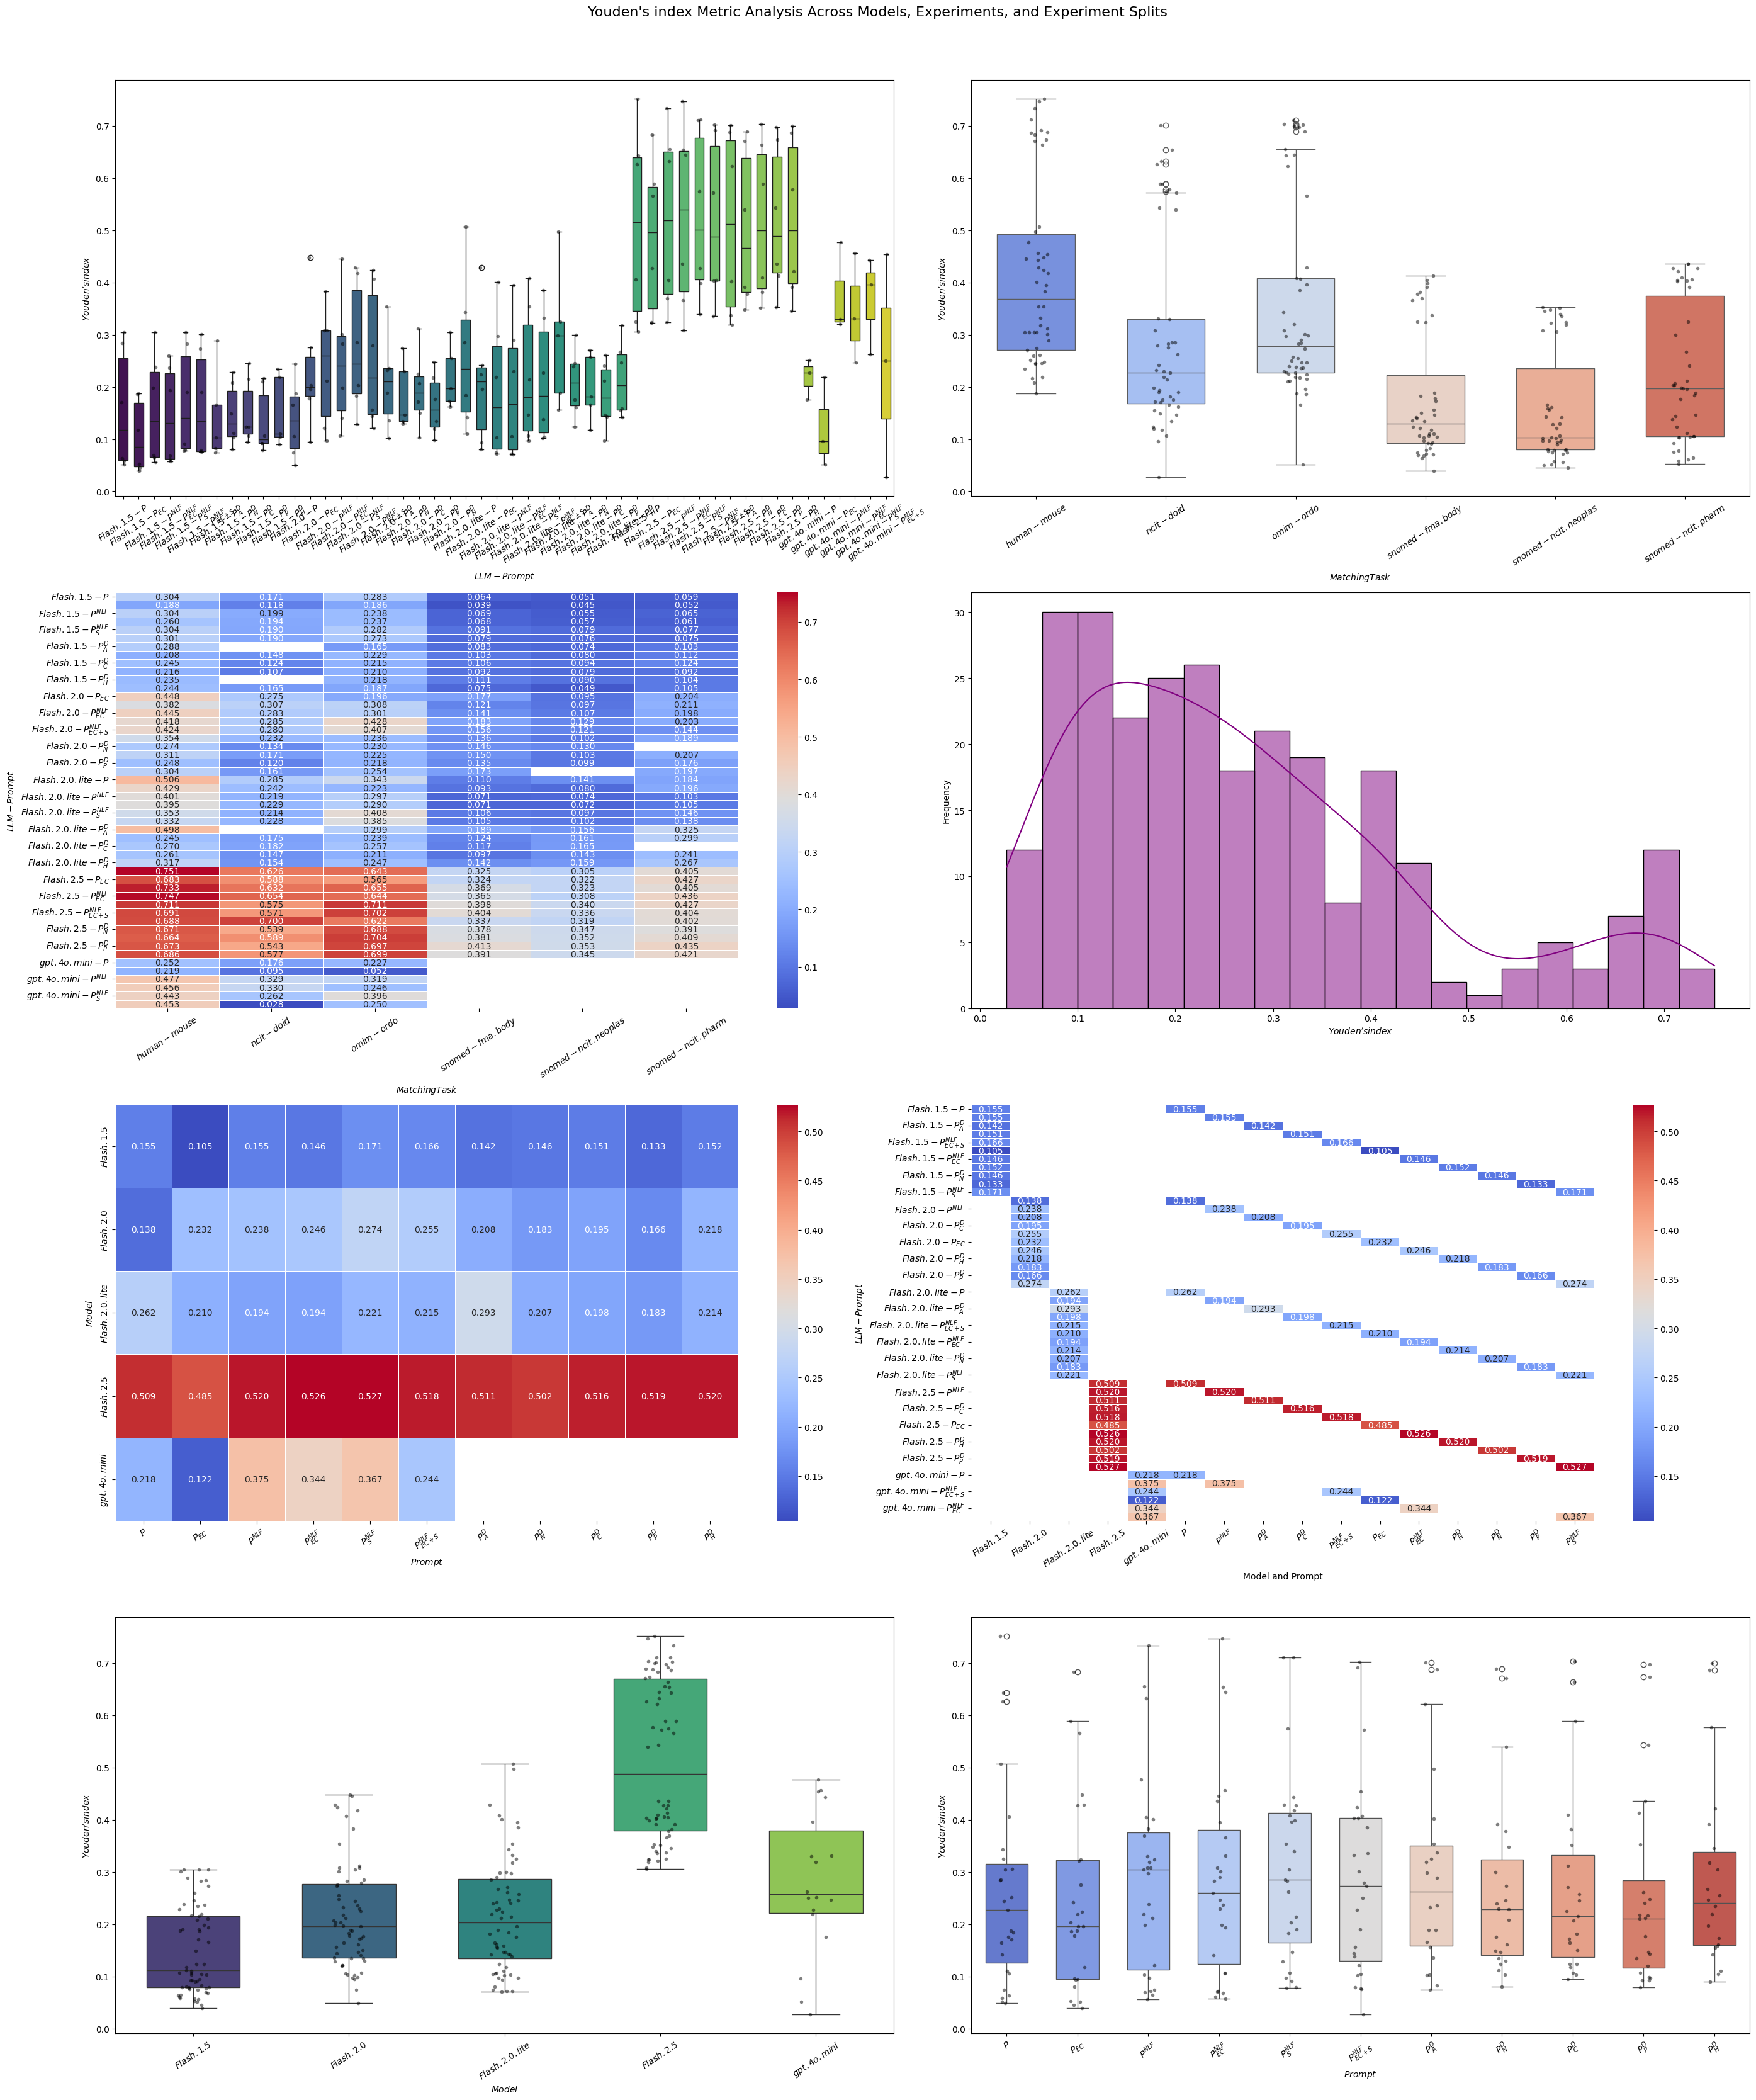

In [226]:
metric = "Youden's index"
# metric = "F1 Score"
experiment_col, left_col, right_col = "Matching Task", "Model", "Prompt"

for suffix in [""]:
    for metric in [metric]:
        # metrics_df = preprocess_metrics_df(pd.read_csv(RUN_DIR / f"all_runs_metrics{suffix}.csv"))
        plot_detaild_analysis(
            metrics_df=metrics_df,
            metric=metric,
            run_col_name="LLM-Prompt",
            experiment_col=experiment_col,
            left_col=left_col,
            right_col=right_col,
            left_col_name="Model",
            right_col_name="Prompt",
            run_separator="-",
            precision=3,
            subfolder_name=f"{metric}{suffix}",
            save_plots=False,
)
        plt.show()

## Copy best results

In [174]:
prompt_type = "direct_entity_with_synonyms"
model = "gemini-2.5-flash-preview-04-17"

In [192]:
for run_metadata in RUNS_METADATA:
    run_name, model_name, subset_name, experiment_name = run_metadata
    run_dir = Path("runs") / run_name
    for file in run_dir.iterdir():
        if prompt_type in str(file) and model in str(file) and str(file).endswith(".csv"):
            logging.info(f"Processing {file} in {file}")
            new_file_path = OUTPUTS_DIR / "best_results" / datetime.now().strftime("%Y-%m-%d") / file.name
            new_file_path.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy(file, new_file_path)

## Gather outputs inference

In [ ]:
outputs_dir = Path("./outputs")
datasets_map = {"anatomy": ["human-mouse"], "largebio": ["fma-nci"], "bioml-2024": ["omim-ordo"]}
models = ["gemini-2.0-flash-lite", "gemini-2.0-flash"]
experiments_subtypes = {"syspromts" : ["base", "natural_language", "ontology_aware", "synonym_aware", "none"]}
experiments_subtypes = {"determinism" : ["0", "1", "2", "3"]}

dfs = []

for dataset, subsets_map in datasets_map.items():
    for set_name in subsets_map:
        for model in models:
            for experiment_type in experiments_subtypes:
                for experiment in experiments_subtypes[experiment_type]:
                    run_subdir = f"{dataset}/{set_name}/{model}/{experiment_type}/{experiment}"
                    metrics_df = pd.read_csv(outputs_dir / run_subdir / "results.csv")

                    for col, value in zip(["Dataset", "SubSet", "Model", "ExperimentType", "ExpName"
                                           ], [dataset, set_name, model, experiment_type, experiment]):
                        if col not in metrics_df.columns:
                            metrics_df[col] = value

                    metrics_df["Run"] = run_subdir
                    dfs.append(metrics_df)

results_df = pd.concat(dfs, ignore_index=True)
results_df = results_df.sort_values(by=["Dataset", "SubSet", "Model"])
results_df = preprocess_metrics_df(results_df)

In [140]:
results_df.head(7)

,Prompt,Accuracy,Precision,Recall,F1 Score,Specificity,Sensitivity,Dataset,Matching Task,Model,ExperimentType,ExpName,Run,Youden's index
31,P,0.7714,0.8792,0.7979,0.8366,0.6981,0.7979,anatomy,human-mouse,Flash.2.0,syspromts,base,anatomy/human-mouse/gemini-2.0-flash/syspromts...,0.4960
37,P,0.7940,0.7853,0.9897,0.8758,0.2547,0.9897,anatomy,human-mouse,Flash.2.0,syspromts,natural_language,anatomy/human-mouse/gemini-2.0-flash/syspromts...,0.2444
43,P,0.8492,0.8718,0.9315,0.9007,0.6226,0.9315,anatomy,human-mouse,Flash.2.0,syspromts,ontology_aware,anatomy/human-mouse/gemini-2.0-flash/syspromts...,0.5541
49,P,0.8191,0.8526,0.9110,0.8808,0.5660,0.9110,anatomy,human-mouse,Flash.2.0,syspromts,synonym_aware,anatomy/human-mouse/gemini-2.0-flash/syspromts...,0.4770
55,P,0.8040,0.8664,0.8664,0.8664,0.6321,0.8664,anatomy,human-mouse,Flash.2.0,syspromts,none,anatomy/human-mouse/gemini-2.0-flash/syspromts...,0.4985
33,P_{EC},0.8116,0.8444,0.9110,0.8764,0.5377,0.9110,anatomy,human-mouse,Flash.2.0,syspromts,base,anatomy/human-mouse/gemini-2.0-flash/syspromts...,0.4487
39,P_{EC},0.8367,0.8328,0.9726,0.8973,0.4623,0.9726,anatomy,human-mouse,Flash.2.0,syspromts,natural_language,anatomy/human-mouse/gemini-2.0-flash/syspromts...,0.4349


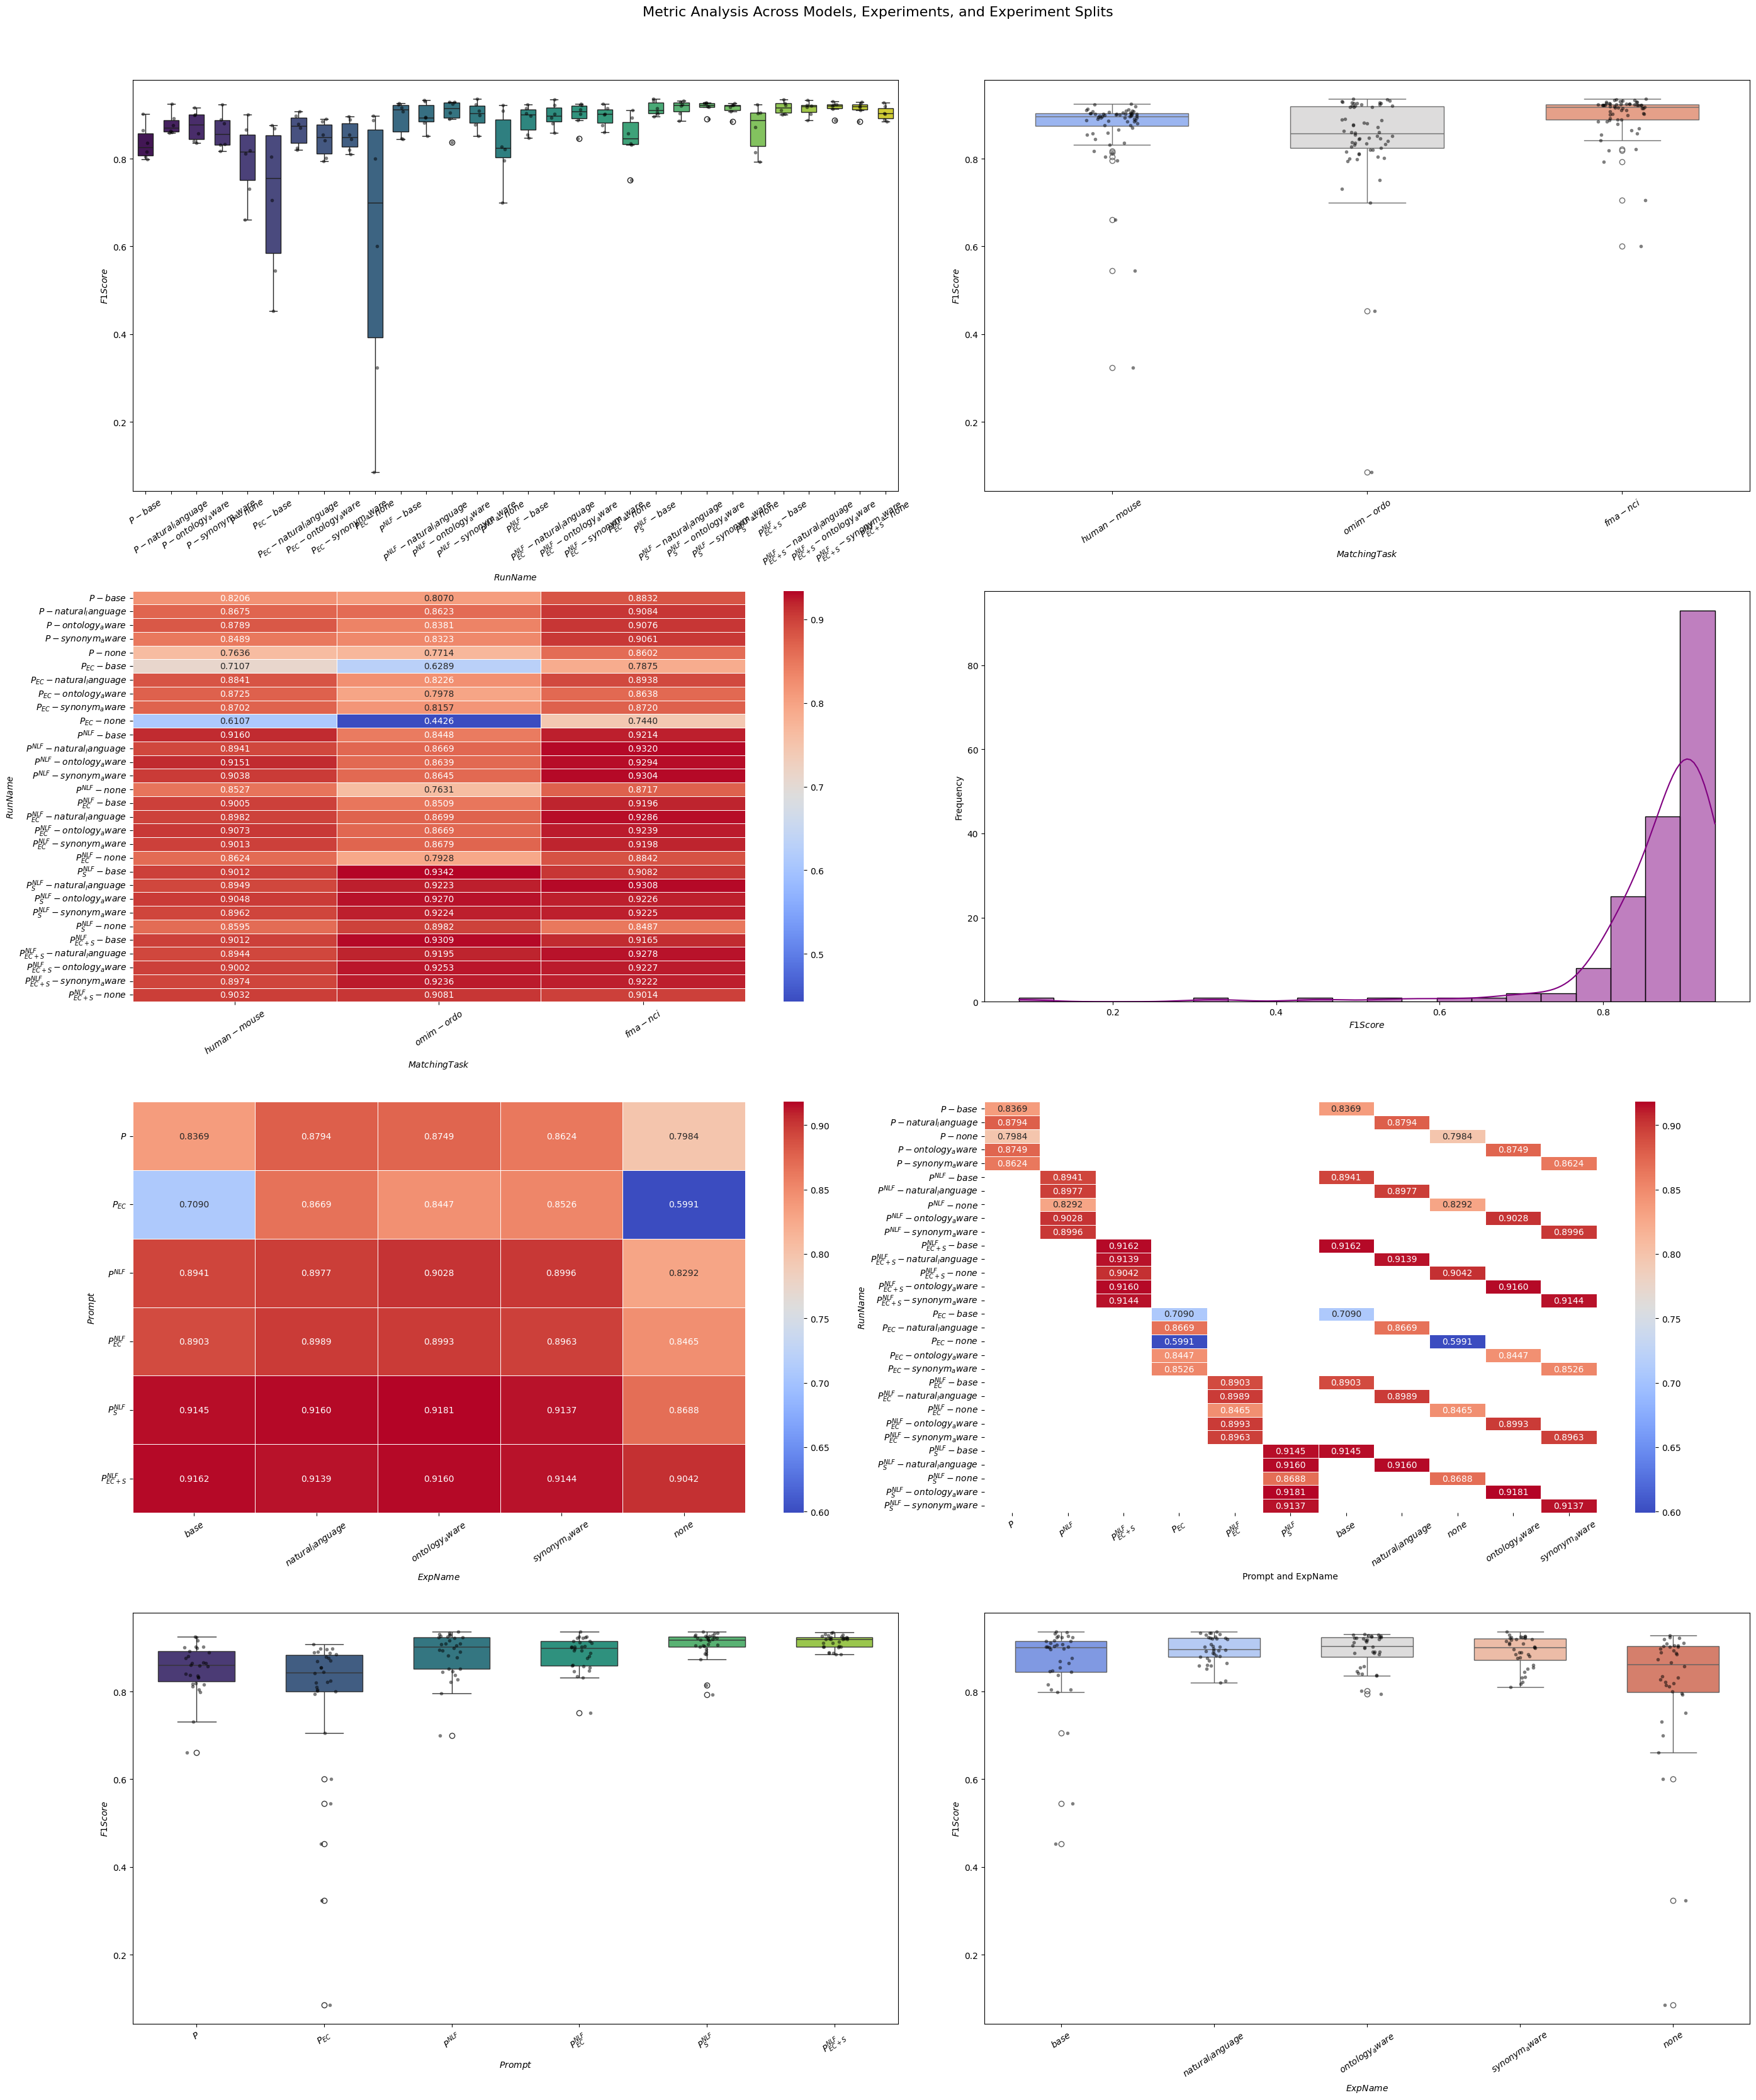

In [ ]:
metrics_df = results_df.copy()
metric = "F1 Score"

experiment_col, left_col, right_col = "Matching Task", "Prompt", "ExpName"

plot_detaild_analysis(
    metrics_df=metrics_df,
    metric=metric,
    run_col_name="RunName",
    experiment_col=experiment_col,
    left_col=left_col,
    right_col=right_col,
    left_col_name=left_col,
    right_col_name=right_col,
    run_separator="-",
    precision=4,
)

## Radar Charts

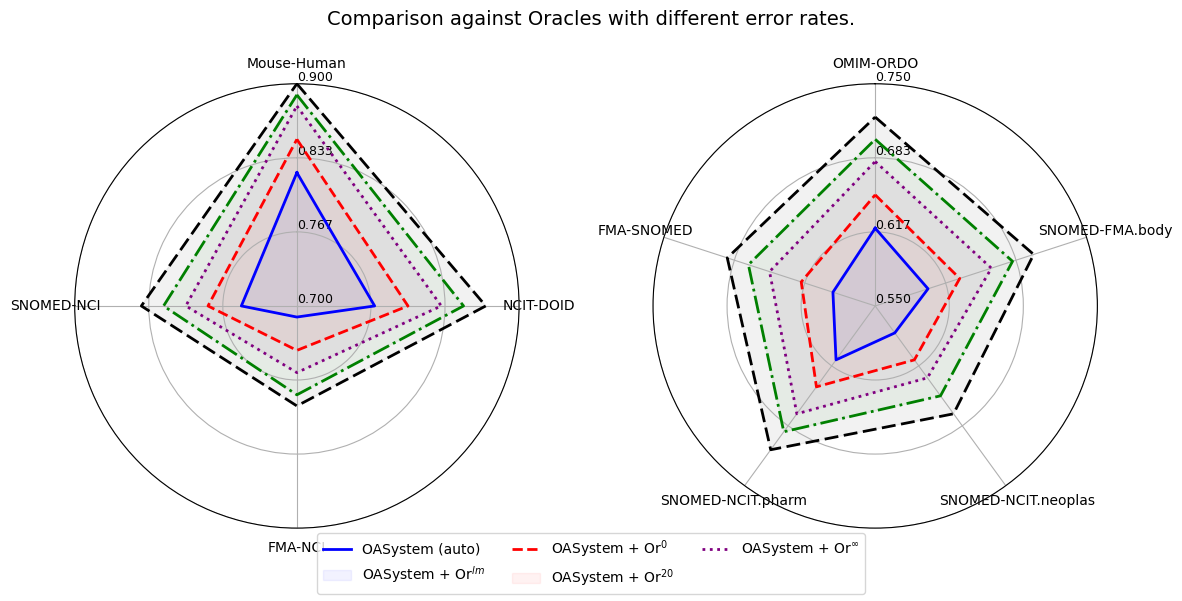

In [ ]:
def make_radar_chart(
    ax: plt.Axes,
    categories: list[str],
    values_list: list[list[float]],
    labels: list[str],
    colors: list[str],
    linestyles: list[str],
    r_range: tuple[float, float],
    title: str,
) -> None:
    angles = np.linspace(0, 2 * np.pi, len(categories), endpoint=False).tolist()
    angles += angles[:1]

    ax.set_theta_offset(np.pi / 2)
    ax.set_theta_direction(-1)
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(categories, fontsize=10)

    ax.set_rlabel_position(0)
    ax.set_ylim(*r_range)
    yticks = np.linspace(r_range[0], r_range[1], 4)
    ax.set_yticks(yticks)
    ax.set_yticklabels([f"{y:.3f}" for y in yticks], fontsize=9)

    for values, label, color, linestyle in zip(values_list, labels, colors, linestyles):
        values += values[:1]
        ax.plot(angles, values, label=label, color=color, linestyle=linestyle, linewidth=2)
        ax.fill(angles, values, color=color, alpha=0.05)

    ax.set_title(title, size=12, y=1.1)


categories1 = ["Mouse-Human", "NCIT-DOID", "FMA-NCI", "SNOMED-NCI"]
values_list1 = [
    [0.82, 0.77, 0.71, 0.75],
    [0.85, 0.80, 0.74, 0.78],
    [0.88, 0.83, 0.76, 0.80],
    [0.89, 0.85, 0.78, 0.82],
    [0.90, 0.87, 0.79, 0.84],
]
categories2 = ["OMIM-ORDO", "SNOMED-FMA.body", "SNOMED-NCIT.neoplas", "SNOMED-NCIT.pharm", "FMA-SNOMED"]
values_list2 = [
    [0.62, 0.60, 0.58, 0.61, 0.59],
    [0.65, 0.63, 0.61, 0.64, 0.62],
    [0.68, 0.66, 0.63, 0.67, 0.65],
    [0.70, 0.68, 0.65, 0.69, 0.67],
    [0.72, 0.70, 0.67, 0.71, 0.69],
]

labels = [
    "OASystem (auto)",
    "OASystem + Or$^{lm}$",
    "OASystem + Or$^{0}$",
    "OASystem + Or$^{20}$",
    r"OASystem + Or$^{\infty}$",
]
colors = ["blue", "red", "purple", "green", "black"]
linestyles = ["solid", "dashed", "dotted", "dashdot", (0, (5, 2))]

fig, axs = plt.subplots(1, 2, subplot_kw={"polar": True}, figsize=(12, 6))
make_radar_chart(axs[0], categories1, [v.copy() for v in values_list1], labels, colors, linestyles, (0.7, 0.9), "")
make_radar_chart(axs[1], categories2, [v.copy() for v in values_list2], labels, colors, linestyles, (0.55, 0.75), "")

fig.legend(labels, loc="lower center", ncol=3, fontsize=10)
fig.suptitle("Comparison against Oracles with different error rates.", fontsize=14)
plt.tight_layout(rect=[0, 0.08, 1, 0.95])
plt.show()
